In [1]:
from pathlib import Path
import os
# The project folder is the folder that contains data/, notebooks/, results/ ...
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
PROJECT_DIR = Path(os.environ.get('PROJECT_DIR', PROJECT_DIR))
print('Project folder:', PROJECT_DIR)
assert (PROJECT_DIR / 'data').exists(), 'Project folder not found - open this notebook from the notebooks folder of the project (see your Steps file)'

Project folder: C:\Users\Reach\Documents\game-chat-toxicity-ml


In [2]:
import re, html, json
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
import matplotlib.pyplot as plt

USE_SAMPLE = False
TRAINABLE  = False        # True would fine-tune the embeddings (not what the paper did)
MAX_EPOCHS = 100
SEED = 42
tf.keras.utils.set_random_seed(SEED)

LAB_DIR, EMB_DIR, RES_DIR = PROJECT_DIR / 'data' / 'labelled', PROJECT_DIR / 'models' / 'emb', PROJECT_DIR / 'results'
(RES_DIR / 'preds').mkdir(parents=True, exist_ok=True); (RES_DIR / 'figures').mkdir(parents=True, exist_ok=True)
prefix = 'sample_' if USE_SAMPLE else ''
train = pd.read_csv(LAB_DIR / f'{prefix}train.csv'); test = pd.read_csv(LAB_DIR / f'{prefix}test.csv')
meta = json.load(open(EMB_DIR / 'vocab.json')); vocab, MAX_LEN = meta['vocab'], meta['max_len']
print('train', len(train), '| test', len(test), '| vocabulary', len(vocab))

train 1583 | test 396 | vocabulary 713


In [3]:
def clean_text(s):
    s = html.unescape(str(s)).lower()
    s = re.sub(r"https?://\S+", " ", s)
    s = re.sub(r"[\u2019'`]", "", s)
    s = re.sub(r"(.)\1{2,}", r"\1\1", s)
    s = re.sub(r"[^a-z0-9?! ]+", " ", s)
    return re.sub(r"\s+", " ", s).strip()

def encode(texts):
    """messages -> integer matrix (n, MAX_LEN); 0 = padding, 1 = unknown word"""
    X = np.zeros((len(texts), MAX_LEN), dtype='int32')
    for i, s in enumerate(texts):
        ids = [vocab.get(w, 1) for w in re.findall(r"[a-z0-9]+|[?!]", clean_text(s))][:MAX_LEN]
        X[i, :len(ids)] = ids
    return X

X_all, y_all = encode(train.text), train.label.values
X_test, y_test = encode(test.text), test.label.values
X_tr, X_val, y_tr, y_val = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=SEED)
print('train/validation/test sizes:', len(X_tr), len(X_val), len(X_test))

train/validation/test sizes: 1266 317 396


In [4]:
EMBEDDINGS = {'word2vec 50-dim': 'w2v_50', 'word2vec 100-dim': 'w2v_100', 'GloVe 50-dim': 'glove_50', 'GloVe 100-dim': 'glove_100'}
ACTIVATIONS = {'ReLU, softmax': ['relu'], 'ReLU, ReLU, softmax': ['relu', 'relu'], 'ReLU, sigmoid, softmax': ['relu', 'sigmoid']}

def build_ff(emb, hidden):
    inp = layers.Input(shape=(MAX_LEN,))
    x = layers.Embedding(emb.shape[0], emb.shape[1], weights=[emb], trainable=TRAINABLE, mask_zero=True)(inp)
    x = layers.GlobalAveragePooling1D()(x)                       # average of the word vectors of the message
    for units, act in zip((64, 32), hidden):
        x = layers.Dense(units, activation=act)(x)
    out = layers.Dense(3, activation='softmax')(x)
    m = models.Model(inp, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m

results, histories = [], {}
for emb_name, emb_file in EMBEDDINGS.items():
    emb = np.load(EMB_DIR / f'{emb_file}.npy')
    for act_name, hidden in ACTIVATIONS.items():
        tf.keras.utils.set_random_seed(SEED)
        model = build_ff(emb, hidden)
        stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
        h = model.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=MAX_EPOCHS, batch_size=64, callbacks=[stop], verbose=0)
        pred = model.predict(X_test, verbose=0).argmax(1)
        f1s = f1_score(y_test, pred, labels=[0, 1, 2], average=None, zero_division=0)
        name = f'Feedforward NN ({act_name}; {emb_name})'
        row = {'model': name, 'family': 'Neural net', 'features': emb_name, 'task': '3-class',
               'accuracy': round(accuracy_score(y_test, pred), 4), 'macro_f1': round(float(f1s.mean()), 4),
               'f1_class0': round(float(f1s[0]), 4), 'f1_class1': round(float(f1s[1]), 4), 'f1_class2': round(float(f1s[2]), 4),
               'val_accuracy': round(max(h.history['val_accuracy']), 4), 'epochs': len(h.history['loss'])}
        results.append(row); histories[name] = h.history
        slug = re.sub(r'[^a-z0-9]+', '_', name.lower()).strip('_')
        pd.DataFrame({'id': test.id.values, 'y_true': y_test, 'y_pred': pred}).to_csv(RES_DIR / 'preds' / f'{slug}.csv', index=False)
        print(f"{name:62s} acc={row['accuracy']:.4f} macroF1={row['macro_f1']:.4f} epochs={row['epochs']}")

Feedforward NN (ReLU, softmax; word2vec 50-dim)                acc=0.7929 macroF1=0.6621 epochs=55
Feedforward NN (ReLU, ReLU, softmax; word2vec 50-dim)          acc=0.8005 macroF1=0.6223 epochs=25
Feedforward NN (ReLU, sigmoid, softmax; word2vec 50-dim)       acc=0.7955 macroF1=0.6460 epochs=44
Feedforward NN (ReLU, softmax; word2vec 100-dim)               acc=0.8106 macroF1=0.6932 epochs=38
Feedforward NN (ReLU, ReLU, softmax; word2vec 100-dim)         acc=0.8030 macroF1=0.6761 epochs=24
Feedforward NN (ReLU, sigmoid, softmax; word2vec 100-dim)      acc=0.8157 macroF1=0.6868 epochs=34
Feedforward NN (ReLU, softmax; GloVe 50-dim)                   acc=0.7904 macroF1=0.6445 epochs=68
Feedforward NN (ReLU, ReLU, softmax; GloVe 50-dim)             acc=0.7929 macroF1=0.6597 epochs=40
Feedforward NN (ReLU, sigmoid, softmax; GloVe 50-dim)          acc=0.7980 macroF1=0.6658 epochs=60
Feedforward NN (ReLU, softmax; GloVe 100-dim)                  acc=0.8056 macroF1=0.6694 epochs=59
Feedforwar

,model,accuracy,macro_f1,f1_class0,f1_class1,f1_class2,epochs
11,"Feedforward NN (ReLU, sigmoid, softmax; GloVe ...",0.8182,0.7121,0.8734,0.7847,0.4783,51
5,"Feedforward NN (ReLU, sigmoid, softmax; word2v...",0.8157,0.6868,0.8836,0.7676,0.4091,34
3,"Feedforward NN (ReLU, softmax; word2vec 100-dim)",0.8106,0.6932,0.8779,0.7571,0.4444,38
10,"Feedforward NN (ReLU, ReLU, softmax; GloVe 100...",0.8106,0.6805,0.8707,0.7708,0.4000,29
9,"Feedforward NN (ReLU, softmax; GloVe 100-dim)",0.8056,0.6694,0.8675,0.7687,0.3721,59
4,"Feedforward NN (ReLU, ReLU, softmax; word2vec ...",0.8030,0.6761,0.8667,0.7616,0.4000,24
1,"Feedforward NN (ReLU, ReLU, softmax; word2vec ...",0.8005,0.6223,0.8701,0.7542,0.2424,25
8,"Feedforward NN (ReLU, sigmoid, softmax; GloVe ...",0.7980,0.6658,0.8584,0.7581,0.3810,60
2,"Feedforward NN (ReLU, sigmoid, softmax; word2v...",0.7955,0.6460,0.8731,0.7394,0.3256,44
0,"Feedforward NN (ReLU, softmax; word2vec 50-dim)",0.7929,0.6621,0.8694,0.7338,0.3830,55


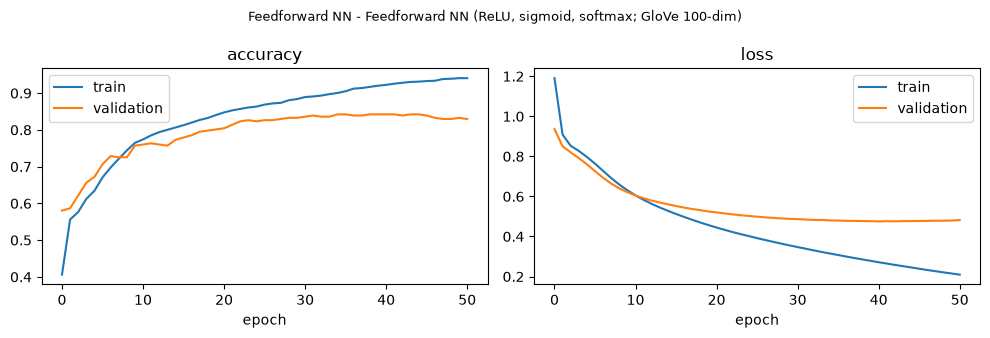

In [5]:
res = pd.DataFrame(results).sort_values('accuracy', ascending=False)
display(res[['model', 'accuracy', 'macro_f1', 'f1_class0', 'f1_class1', 'f1_class2', 'epochs']])
if not USE_SAMPLE:
    res.to_csv(RES_DIR / 'nn_ff_results.csv', index=False)

best = res.iloc[0].model
h = histories[best]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(h['accuracy'], label='train'); ax[0].plot(h['val_accuracy'], label='validation'); ax[0].set_title('accuracy'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot(h['loss'], label='train'); ax[1].plot(h['val_loss'], label='validation'); ax[1].set_title('loss'); ax[1].set_xlabel('epoch'); ax[1].legend()
fig.suptitle('Feedforward NN - ' + best, fontsize=9); plt.tight_layout()
if not USE_SAMPLE: plt.savefig(RES_DIR / 'figures' / 'ff_curves.png', dpi=150)
plt.show()